# 01 - Exploratory Data Analysis
Heart Disease UCI (Cleveland). Run `python -m src.download_data` first (or let `load_clean()` do it).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # so `src` is importable from notebooks/
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt, seaborn as sns, pandas as pd, numpy as np
from src import config
from src.data import load_clean
sns.set_theme(style="whitegrid", context="notebook")
OUT = config.ROOT / "screenshots" / "eda"; OUT.mkdir(parents=True, exist_ok=True)
df = load_clean()
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0


In [2]:
print(df.shape)
df.info()
df.describe().T

(303, 14)
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    float64
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(5), int64(9)
memory usage: 33.3 KB


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## Class balance

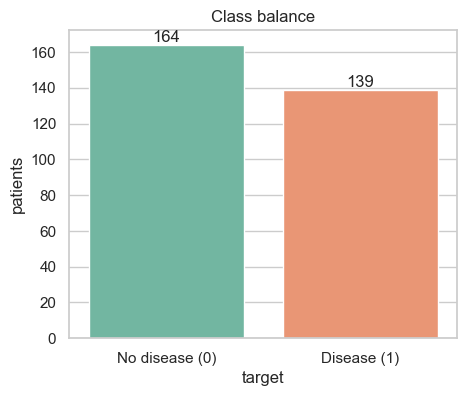

target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [3]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="target", data=df, hue="target", palette="Set2", legend=False, ax=ax)
ax.set_xticks([0, 1], ["No disease (0)", "Disease (1)"])
for c in ax.containers: ax.bar_label(c)
ax.set_title("Class balance"); ax.set_ylabel("patients")
fig.savefig(OUT / "class_balance.png", dpi=150, bbox_inches="tight"); plt.show()
print(df.target.value_counts(normalize=True).round(3))

**Insight (edit):** The dataset is fairly balanced, with about 54% healthy (164) and 46% diseased (139). No resampling is needed, and accuracy is a reasonable metric here. Recall still matters most clinically, because missing a sick patient costs more than a false alarm.

## Histograms of numeric features

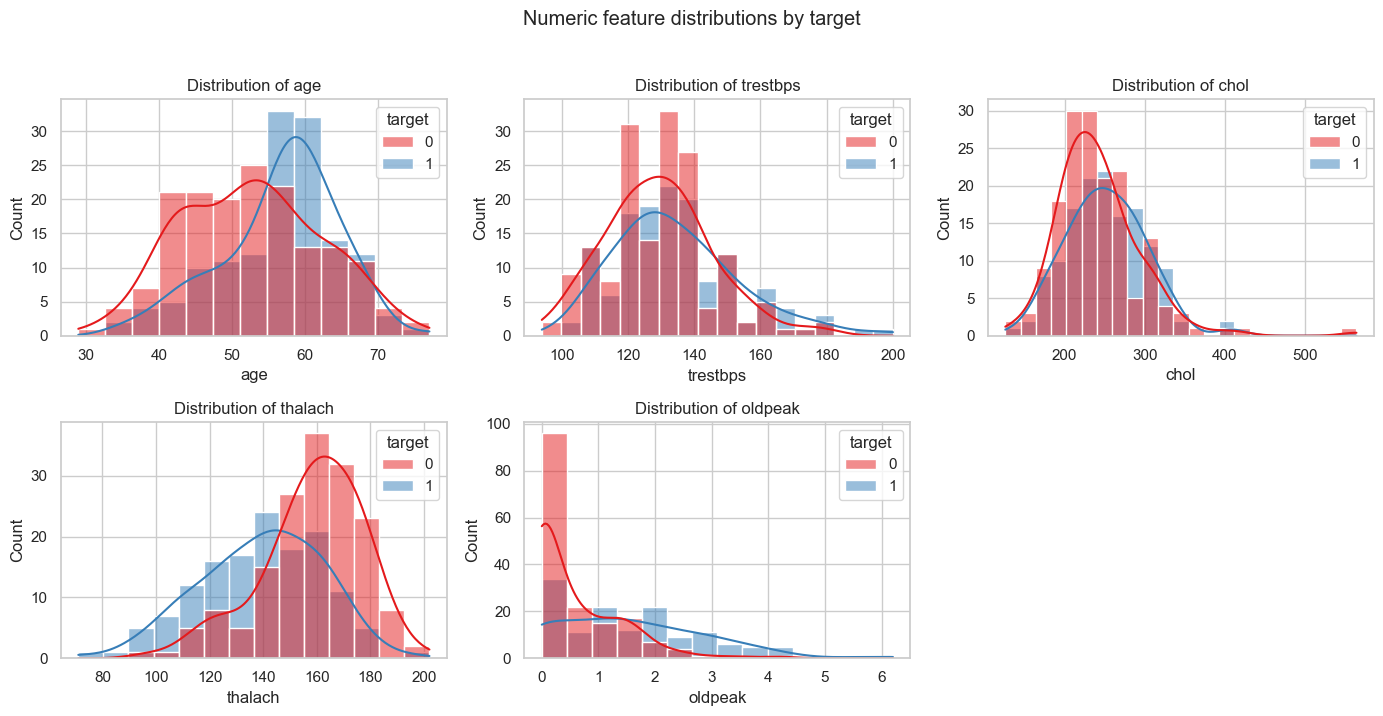

In [4]:
num = config.NUMERIC_FEATURES
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num):
    sns.histplot(data=df, x=col, hue="target", kde=True, palette="Set1", ax=ax)
    ax.set_title(f"Distribution of {col}")
axes.ravel()[-1].axis("off")
fig.suptitle("Numeric feature distributions by target", y=1.02)
fig.tight_layout(); fig.savefig(OUT / "histograms.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight (edit):** Age is roughly bell-shaped and peaks in the 50s–60s. Max heart rate (thalach) is skewed lower for diseased patients, and oldpeak is heavily right-skewed with many zeros, with higher values mostly in the disease group. Cholesterol and resting blood pressure overlap heavily between the two groups, so they look weak on their own.

## Correlation heatmap

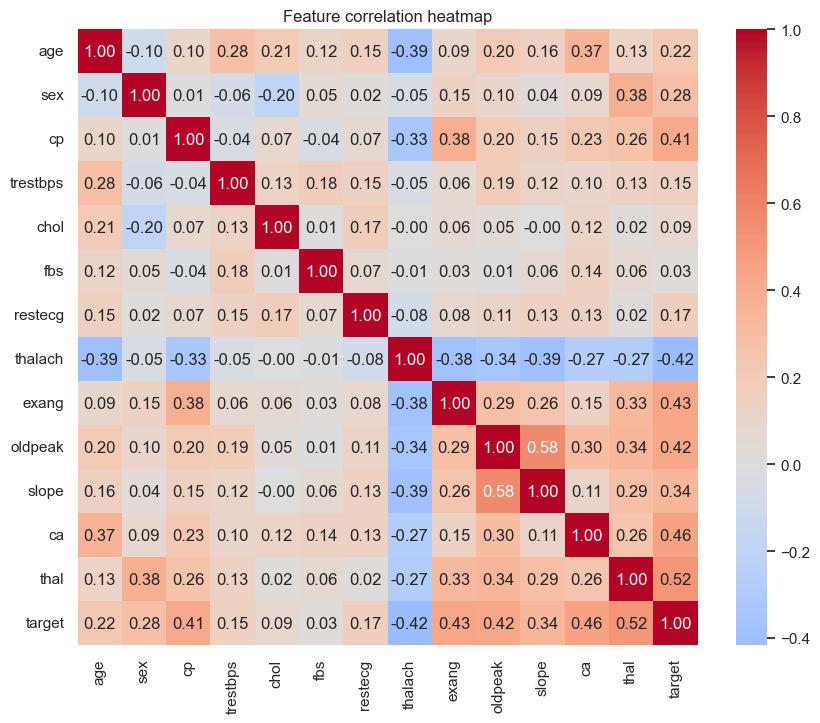

thal        0.522057
ca          0.460033
exang       0.431894
oldpeak     0.424510
thalach    -0.417167
cp          0.414446
slope       0.339213
sex         0.276816
age         0.223120
restecg     0.169202
trestbps    0.150825
chol        0.085164
fbs         0.025264
Name: target, dtype: float64

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Feature correlation heatmap")
fig.savefig(OUT / "correlation_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()
df.corr()["target"].drop("target").sort_values(key=abs, ascending=False)

**Insight (edit):** The strongest links to the target are thal, ca, oldpeak, exang, cp and thalach, each around 0.4–0.5 in absolute value. thalach correlates negatively, so a lower peak heart rate goes with disease. Cholesterol and fasting blood sugar are close to zero. No pair of features is strongly collinear, though oldpeak and slope (about 0.6) and age and thalach (about −0.4) are worth a mention.

## Boxplots by target

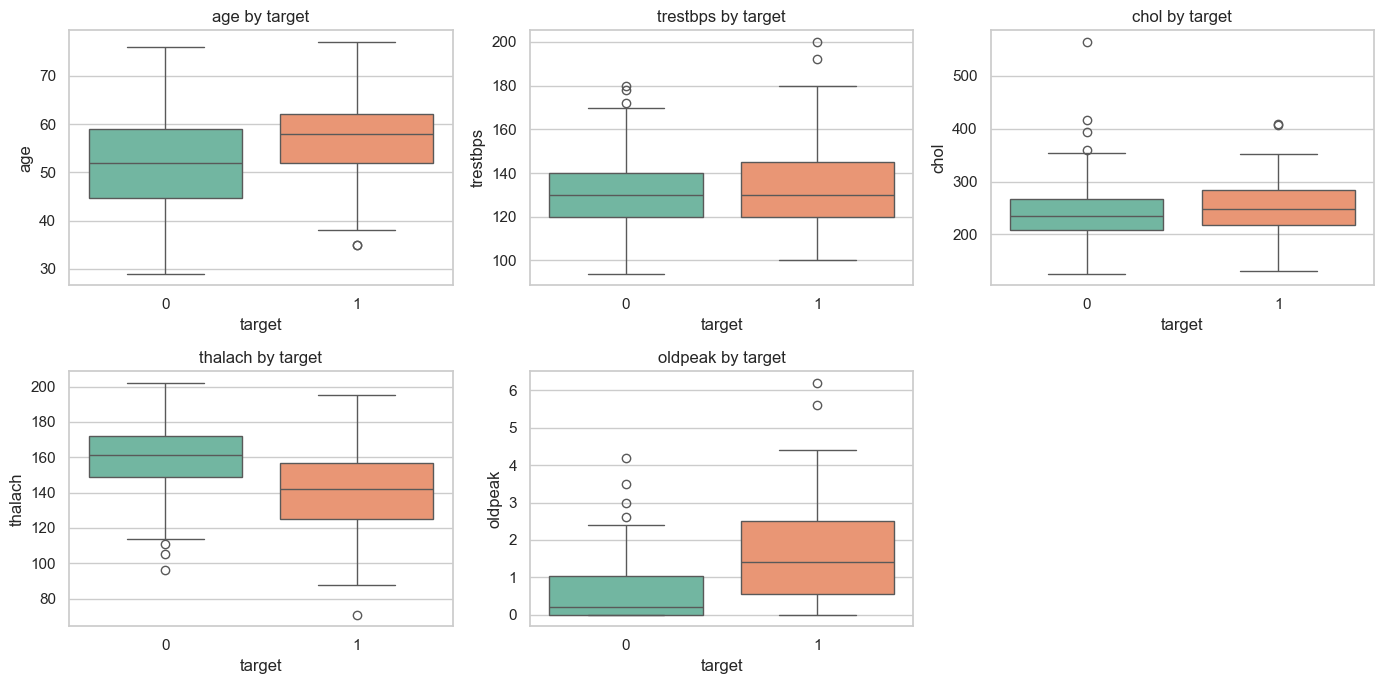

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num):
    sns.boxplot(data=df, x="target", y=col, hue="target", palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{col} by target")
axes.ravel()[-1].axis("off")
fig.tight_layout(); fig.savefig(OUT / "boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight** The diseased group has a lower median thalach and a higher median oldpeak, with only a slightly higher median age. chol and trestbps medians are nearly identical across groups, and chol has a few extreme outliers (the maximum is around 560). I kept the outliers because they are plausible clinical values. Scaling and tree-based models limit their influence.
    

## Categorical features vs target

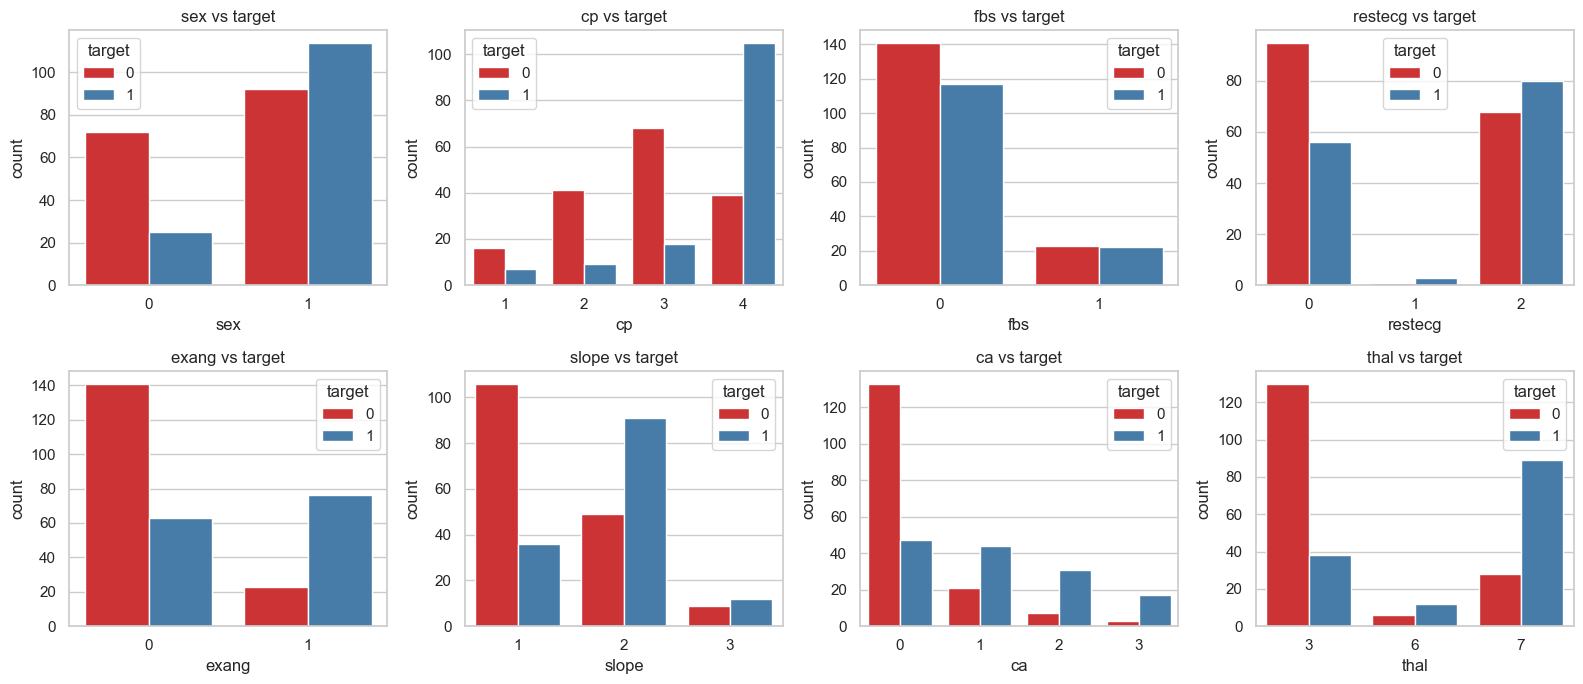

In [7]:
cats = config.CATEGORICAL_FEATURES
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), cats):
    sns.countplot(data=df, x=col, hue="target", palette="Set1", ax=ax)
    ax.set_title(f"{col} vs target")
fig.tight_layout(); fig.savefig(OUT / "categorical_vs_target.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight** Chest pain type 4 (asymptomatic) has by far the highest share of disease. Exercise-induced angina (exang=1), one or more major vessels (ca > 0) and reversible-defect thalassemia (thal=7) also point strongly toward disease. Males have a higher disease share than females, and fbs shows almost no difference.

## Missing values & cleaning notes
`ca` (4 rows) and `thal` (2 rows) were `?` in the raw file; imputed with the **mode** (they are categorical). Target `num` 0-4 binarised to 0/1. Edit this text with your own justification.

**Insight** ca had 4 missing values and thal had 2, all marked ?. I used mode imputation because both are categorical, and with only 6 affected rows it avoids discarding data from such a small dataset. I also converted the original 0–4 label into binary: 0 means no disease, 1–4 means disease.